# Phase 8 — GRPO agentique : apprendre à un modèle à utiliser un outil

Jusqu'ici, ton modèle **parlait**. Ici, un modèle va **agir** : il dispose d'une calculatrice, et il doit apprendre **tout seul**, par renforcement, quand et comment s'en servir.

**Pourquoi un autre modèle ?** Le GRPO renforce ce qu'un modèle réussit *parfois*. Ton modèle de 46 M ne réussirait jamais à utiliser un outil : rien à renforcer. On prend donc **Qwen2.5-0.5B-Instruct** (494 M de paramètres, licence Apache 2.0), dix fois plus gros.

**La tâche :** des problèmes de calcul en français, avec de grands nombres (« 37 caisses de 856 pommes »). Trop durs de tête pour un petit modèle, faciles avec une calculatrice.

**Le plan :**
1. mesurer le modèle **sans outil**, puis **avec l'outil mais sans entraînement** ;
2. l'entraîner avec **GRPO**, écrit à la main ;
3. le remesurer. Est-ce qu'il a appris à se servir de l'outil ?

**Kaggle :** GPU T4 x2 (on en utilise un), Internet On. L'entraînement est le plus long du projet après le pré-entraînement : compte environ une heure (estimation, la cellule affiche le temps réel).

In [1]:
   !pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
   !pip install -U transformers peft huggingface_hub

  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)


In [3]:
import os, re, json, math, time, random
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

device = "cuda"
print("GPU :", torch.cuda.get_device_name(0))
MODELE = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODELE)
tok.padding_side = "left"        # pour générer en lot, on aligne les textes à droite
modele = AutoModelForCausalLM.from_pretrained(MODELE, dtype=torch.float32).to(device)
print(f"{sum(p.numel() for p in modele.parameters()) / 1e6:.0f} M de paramètres")

GPU : Tesla T4


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

494 M de paramètres


## 1. Les problèmes, la calculatrice et la récompense

**Les problèmes** sont générés par programme : on connaît donc toujours la bonne réponse. C'est ce qui rend la récompense **vérifiable**, la condition du GRPO.

**L'outil** : quand le modèle écrit `<calc>856*37</calc>`, on **arrête** la génération, on calcule, on ajoute `<resultat>31672</resultat>` au texte, et le modèle **reprend**. Le modèle ne fait que du texte : c'est le programme autour de lui qui exécute l'outil. Un agent, c'est exactement ça : un modèle + des outils + une boucle.

**La récompense**, pour chaque essai :
- **1** si la réponse finale est juste ;
- **0,1** si elle est fausse mais au bon format (`<reponse>…</reponse>`) ;
- **0** sinon.

Remarque ce qu'on ne récompense **pas** : l'usage de l'outil. On récompense seulement le **résultat**. Si le modèle apprend à utiliser la calculatrice, c'est parce que c'est le moyen le plus sûr d'avoir juste. Personne ne le lui dit.

In [4]:
def probleme(rng):
    a, b, c = rng.randint(120, 999), rng.randint(13, 98), rng.randint(10, 99)
    return rng.choice([
        (f"Un fermier récolte {a} caisses contenant chacune {b} pommes. Combien de pommes a-t-il en tout ?", a * b),
        (f"Une salle compte {b} rangées de {a} sièges. {c} sièges sont occupés. Combien de sièges sont libres ?", a * b - c),
        (f"Un camion transporte {a} kg par voyage. Il fait {b} voyages, puis livre encore {c} kg. Combien de kg a-t-il transportés au total ?", a * b + c),
        (f"{b} amis se partagent équitablement {a * b} euros. Combien chacun reçoit-il ?", a),
        (f"Une usine fabrique {a} pièces par jour pendant {b} jours. Combien de pièces a-t-elle fabriquées ?", a * b),
    ])

def calculer(expression):
    """La calculatrice : seulement des chiffres et + - * / ( ). Rien d'autre n'est exécuté."""
    expression = expression.replace("×", "*").replace("x", "*").replace(" ", "")
    if not re.fullmatch(r"[\d+\-*/().]{1,60}", expression):
        return "erreur"
    try:
        r = eval(expression, {"__builtins__": {}})
        return str(int(r)) if float(r).is_integer() else f"{r:.4f}"
    except Exception:
        return "erreur"

def extraire(texte):
    m = re.findall(r"<reponse>\s*(-?[\d\s.,]+?)\s*</reponse>", texte)
    if not m:
        return None
    try:
        return int(m[-1].replace(" ", "").replace(".", "").replace(",", ""))
    except ValueError:
        return None

def recompense(texte, attendu):
    r = extraire(texte)
    return 0.0 if r is None else (1.0 if r == attendu else 0.1)

rng = random.Random(0)
for _ in range(3):
    print(probleme(rng))
print("\nTest de la calculatrice :", calculer("856*37"), "|", calculer("__import__('os')"))

('Un fermier récolte 984 caisses contenant chacune 62 pommes. Combien de pommes a-t-il en tout ?', 61008)
('78 amis se partagent équitablement 30030 euros. Combien chacun reçoit-il ?', 385)
('Un camion transporte 922 kg par voyage. Il fait 51 voyages, puis livre encore 71 kg. Combien de kg a-t-il transportés au total ?', 47093)

Test de la calculatrice : 31672 | erreur


## 2. La boucle agent : générer, exécuter l'outil, reprendre

Pour chaque essai, on garde le texte en **segments**, chacun marqué :
- **produit par le modèle** → il apprendra dessus ;
- **injecté par l'outil** (`<resultat>…</resultat>`) → il n'apprendra **pas** dessus.

C'est le même principe que le **masquage du SFT** : on n'entraîne le modèle que sur ce qu'il a lui-même écrit. Sinon, il apprendrait à *inventer* des résultats de calculatrice au lieu de l'appeler.

In [5]:
SYSTEME = """Tu résous des problèmes de calcul. Tu disposes d'une calculatrice.
Pour l'utiliser, écris une opération entre <calc> et </calc>, par exemple <calc>125*48</calc>.
Le résultat te sera donné entre <resultat> et </resultat>.
Quand tu as trouvé, donne la réponse finale (un nombre entier) entre <reponse> et </reponse>.

Exemple :
Problème : Un libraire vend 215 livres à 36 euros chacun. Combien gagne-t-il ?
<calc>215*36</calc><resultat>7740</resultat>
Il gagne 7740 euros. <reponse>7740</reponse>"""

SYSTEME_SANS_OUTIL = """Tu résous des problèmes de calcul de tête, sans calculatrice.
Donne la réponse finale (un nombre entier) entre <reponse> et </reponse>."""

@torch.no_grad()
def deroulements(problemes, avec_outil=True, n=1, temperature=1.0, max_tours=3, max_tokens=160):
    """Fait jouer le modèle sur chaque problème, `n` fois. Renvoie les trajectoires."""
    trajs = []
    for enonce, attendu in problemes:
        msgs = [{"role": "system", "content": SYSTEME if avec_outil else SYSTEME_SANS_OUTIL},
                {"role": "user", "content": enonce}]
        prompt = tok(tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False),
                     add_special_tokens=False).input_ids
        for _ in range(n):
            trajs.append({"prompt": prompt, "segments": [], "texte": "", "attendu": attendu, "fini": False})
    modele.eval()
    for tour in range(max_tours):
        actifs = [t for t in trajs if not t["fini"]]
        for k in range(0, len(actifs), 48):                       # par paquets, pour la mémoire
            paquet = actifs[k:k + 48]
            entrees = [t["prompt"] + [i for s, _ in t["segments"] for i in s] for t in paquet]
            L = max(map(len, entrees))
            x = torch.tensor([[tok.pad_token_id] * (L - len(e)) + e for e in entrees], device=device)
            masque = (x != tok.pad_token_id).long()
            for j, e in enumerate(entrees):
                masque[j, L - len(e):] = 1
            options = dict(do_sample=True, temperature=temperature) if temperature > 0 else dict(do_sample=False)
            with torch.autocast("cuda", dtype=torch.float16):
                sortie = modele.generate(input_ids=x, attention_mask=masque, max_new_tokens=max_tokens,
                                         stop_strings=["</calc>"] if avec_outil else None, tokenizer=tok,
                                         pad_token_id=tok.pad_token_id, **options)
            for t, s in zip(paquet, sortie[:, L:].tolist()):
                gen = []
                for i in s:
                    if i == tok.pad_token_id:
                        break
                    gen.append(i)
                texte = tok.decode(gen)
                t["segments"].append((gen, True))                 # écrit par le modèle : appris
                t["texte"] += texte
                appels = re.findall(r"<calc>(.*?)</calc>", texte, re.S)
                if avec_outil and appels and "<reponse>" not in texte and tour < max_tours - 1:
                    injecte = f"<resultat>{calculer(appels[-1])}</resultat>"
                    t["segments"].append((tok(injecte, add_special_tokens=False).input_ids, False))  # outil : pas appris
                    t["texte"] += injecte
                else:
                    t["fini"] = True
    for t in trajs:
        t["recompense"] = recompense(t["texte"], t["attendu"])
        t["outil"] = "<calc>" in t["texte"]
    return trajs

def evaluer(problemes, avec_outil):
    trajs = deroulements(problemes, avec_outil=avec_outil, temperature=0)    # glouton : pas de hasard
    return {"exactitude": np.mean([t["recompense"] == 1.0 for t in trajs]),
            "format": np.mean([extraire(t["texte"]) is not None for t in trajs]),
            "outil": np.mean([t["outil"] for t in trajs])}, trajs

## 3. Avant l'entraînement : les deux points de référence

Sur 100 problèmes **jamais utilisés pour l'entraînement** :
- **sans outil** : le modèle calcule de tête ;
- **avec outil** : il a la calculatrice et l'exemple, mais aucun entraînement.

Regarde surtout la colonne **outil** de la 2e ligne. Si le modèle n'utilisait **jamais** la calculatrice et ne réussissait **jamais**, le GRPO ne pourrait rien faire : il n'y aurait aucune bonne réponse à renforcer.

In [6]:
rng_test = random.Random(123)
test = [probleme(rng_test) for _ in range(100)]
mesures = {}
t0 = time.time()
mesures["sans outil"], _ = evaluer(test, avec_outil=False)
mesures["avec outil, avant GRPO"], trajs_avant = evaluer(test, avec_outil=True)
for nom, m in mesures.items():
    print(f"{nom:<24} | exactitude {m['exactitude']:.0%} | format respecté {m['format']:.0%} | utilise l'outil {m['outil']:.0%}")
print(f"({time.time() - t0:.0f} s)")
print("\nExemple, avant entraînement :\n", trajs_avant[0]["texte"][:400])

sans outil               | exactitude 0% | format respecté 3% | utilise l'outil 0%
avec outil, avant GRPO   | exactitude 7% | format respecté 13% | utilise l'outil 60%
(38 s)

Exemple, avant entraînement :
 <calc>(8131/47)</calc><<resultat>173</resultat>></calc>



## 4. Le GRPO, écrit à la main

À chaque étape :
1. on prend **4 problèmes** et on fait jouer le modèle **8 fois** sur chacun (avec du hasard : température 1) ;
2. on calcule la récompense de chaque essai ;
3. **l'avantage** : pour chaque essai, on compare sa récompense à la **moyenne de son groupe** (les 8 essais du même problème) :
   `avantage = (récompense − moyenne du groupe) / écart-type du groupe` ;
4. on pousse le modèle à rendre **plus probables** les essais à avantage positif, et **moins probables** ceux à avantage négatif.

C'est tout l'esprit de GRPO (*Group Relative Policy Optimization*) : pas besoin d'un second modèle « critique » pour juger, le groupe sert de référence. Un essai n'est pas « bon » dans l'absolu, il est **meilleur que ses frères**.

**Point important :** si les 8 essais d'un problème ont la **même** récompense (tous justes ou tous faux), l'avantage vaut 0 partout : ce groupe n'apprend rien. Le signal vient de la **diversité** des essais.

**LoRA** : au lieu de modifier les 494 M de paramètres, on ajoute de petites matrices d'ajustement (environ 1 % des paramètres). Moins de mémoire, et le modèle d'origine reste intact.

In [9]:
modele = get_peft_model(modele, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0,
                        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
modele.print_trainable_parameters()

ETAPES, PROBLEMES, ESSAIS, LR, MICRO = 60, 4, 8, 5e-5, 4
optimiseur = torch.optim.AdamW([p for p in modele.parameters() if p.requires_grad], lr=LR, weight_decay=0.0)
scaler = torch.amp.GradScaler()
rng_train = random.Random(0)
journal = []

def pas_grpo(trajs):
    # 3. avantages, par groupe de ESSAIS
    for g in range(0, len(trajs), ESSAIS):
        groupe = trajs[g:g + ESSAIS]
        r = np.array([t["recompense"] for t in groupe])
        for t in groupe:
            t["avantage"] = 0.0 if r.std() < 1e-6 else (t["recompense"] - r.mean()) / (r.std() + 1e-4)
    utiles = [t for t in trajs if t["avantage"] != 0.0]
    if not utiles:
        return 0
    # 4. gradient : avantage x log-probabilité des tokens écrits par le modèle
    n_tokens = sum(len(s) for t in utiles for s, appris in t["segments"] if appris)
    modele.train()
    for k in range(0, len(utiles), MICRO):
        lot = utiles[k:k + MICRO]
        seqs = [t["prompt"] + [i for s, _ in t["segments"] for i in s] for t in lot]
        masques = [[0] * len(t["prompt"]) + [int(a) for s, a in t["segments"] for _ in s] for t in lot]
        L = max(map(len, seqs))
        x = torch.tensor([s + [tok.pad_token_id] * (L - len(s)) for s in seqs], device=device)
        m = torch.tensor([mm + [0] * (L - len(mm)) for mm in masques], device=device, dtype=torch.float32)
        att = torch.tensor([[1] * len(s) + [0] * (L - len(s)) for s in seqs], device=device)
        A = torch.tensor([t["avantage"] for t in lot], device=device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = modele(input_ids=x, attention_mask=att).logits[:, :-1]
        lp = torch.log_softmax(logits.float(), -1).gather(2, x[:, 1:, None]).squeeze(2)
        perte = -(A[:, None] * lp * m[:, 1:]).sum() / n_tokens
        scaler.scale(perte).backward()
    scaler.unscale_(optimiseur)
    torch.nn.utils.clip_grad_norm_([p for p in modele.parameters() if p.requires_grad], 1.0)
    scaler.step(optimiseur); scaler.update()
    optimiseur.zero_grad(set_to_none=True)
    return len(utiles)

t0 = time.time()
for etape in range(1, ETAPES + 1):
    problemes = [probleme(rng_train) for _ in range(PROBLEMES)]
    trajs = deroulements(problemes, avec_outil=True, n=ESSAIS, temperature=1.0)   # 1-2. jouer et noter
    n_utiles = pas_grpo(trajs)
    ligne = {"étape": etape,
             "récompense": np.mean([t["recompense"] for t in trajs]),
             "exactitude": np.mean([t["recompense"] == 1.0 for t in trajs]),
             "outil": np.mean([t["outil"] for t in trajs]),
             "essais utiles": n_utiles / len(trajs)}
    journal.append(ligne)
    if etape % 5 == 0 or etape == 1:
        reste = (ETAPES - etape) * (time.time() - t0) / etape
        print(f"étape {etape:>3} | récompense {ligne['récompense']:.2f} | justes {ligne['exactitude']:.0%} | "
              f"outil {ligne['outil']:.0%} | essais utiles {ligne['essais utiles']:.0%} | reste ~{reste / 60:.0f} min")

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
étape   1 | récompense 0.01 | justes 0% | outil 38% | essais utiles 50% | reste ~21 min
étape   5 | récompense 0.32 | justes 25% | outil 81% | essais utiles 50% | reste ~23 min
étape  10 | récompense 0.80 | justes 78% | outil 100% | essais utiles 25% | reste ~15 min
étape  15 | récompense 0.78 | justes 75% | outil 100% | essais utiles 0% | reste ~12 min
étape  20 | récompense 1.00 | justes 100% | outil 100% | essais utiles 0% | reste ~10 min
étape  25 | récompense 0.55 | justes 50% | outil 100% | essais utiles 50% | reste ~9 min
étape  30 | récompense 1.00 | justes 100% | outil 100% | essais utiles 0% | reste ~7 min
étape  35 | récompense 0.92 | justes 91% | outil 100% | essais utiles 25% | reste ~6 min
étape  40 | récompense 1.00 | justes 100% | outil 100% | essais utiles 0% | reste ~4 min
étape  45 | récompense 1.00 | justes 100% | outil 100% | essais utiles 0% | reste ~3 min
étape  50 | récompense 1.00 | ju

## 5. Les courbes d'apprentissage

Les courbes sont **bruitées** : chaque étape ne voit que 4 problèmes. On trace aussi une moyenne glissante sur 10 étapes pour voir la tendance.

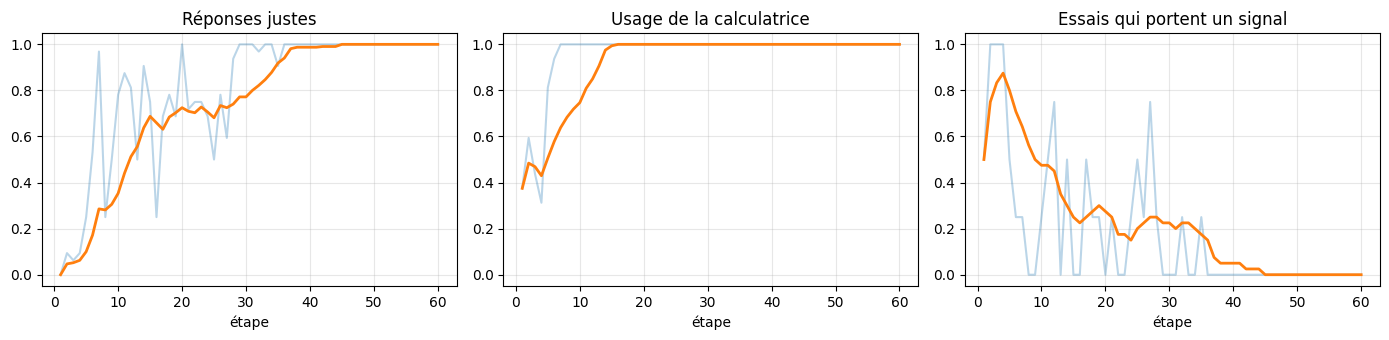

In [10]:
import pandas as pd
j = pd.DataFrame(journal)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, titre in [(axes[0], "exactitude", "Réponses justes"), (axes[1], "outil", "Usage de la calculatrice"),
                       (axes[2], "essais utiles", "Essais qui portent un signal")]:
    ax.plot(j["étape"], j[col], alpha=.3)
    ax.plot(j["étape"], j[col].rolling(10, min_periods=1).mean(), lw=2)
    ax.set_title(titre); ax.set_xlabel("étape"); ax.set_ylim(-0.05, 1.05); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Après l'entraînement : le verdict

Les mêmes 100 problèmes de test qu'au début, en décodage glouton.

In [11]:
mesures["avec outil, après GRPO"], trajs_apres = evaluer(test, avec_outil=True)
print(f"{'':<24} | {'exactitude':>10} | {'format':>7} | {'outil':>6}")
print("-" * 58)
for nom, m in mesures.items():
    print(f"{nom:<24} | {m['exactitude']:>10.0%} | {m['format']:>7.0%} | {m['outil']:>6.0%}")

print("\n--- Le même problème, avant et après ---")
for i in range(3):
    print("\n❓", test[i][0], f"(attendu : {test[i][1]})")
    print("AVANT :", trajs_avant[i]["texte"][:300].replace("\n", " "))
    print("APRÈS :", trajs_apres[i]["texte"][:300].replace("\n", " "))

                         | exactitude |  format |  outil
----------------------------------------------------------
sans outil               |         0% |      3% |     0%
avec outil, avant GRPO   |         7% |     13% |    60%
avec outil, après GRPO   |       100% |    100% |   100%

--- Le même problème, avant et après ---

❓ 47 amis se partagent équitablement 8131 euros. Combien chacun reçoit-il ? (attendu : 173)
AVANT : <calc>(8131/47)</calc><<resultat>173</resultat>></calc> 
APRÈS : <calc>(8131/47)</calc><<resultat>173</resultat> <reponse>173</reponse>.<|im_end|>

❓ 26 amis se partagent équitablement 10192 euros. Combien chacun reçoit-il ? (attendu : 392)
AVANT : <calc>(10192/26)</calc><<resultat>392</resultat>><calc>(10192/26)</calc><<resultat>392</resultat>><calc>(10192/26)</calc><
APRÈS : <calc>(10192/26)</calc><<resultat>392</resultat> <reponse>392</reponse>.<|im_end|>

❓ Un camion transporte 669 kg par voyage. Il fait 84 voyages, puis livre encore 52 kg. Combien de kg a-t-i

## 7. Où se trompe-t-il encore ?

Un bon évaluateur regarde ses erreurs. On classe les échecs après entraînement :
- **pas d'outil** : il a tenté de tête ;
- **mauvaise opération** : il a appelé l'outil, mais avec le mauvais calcul (par exemple il a oublié le « − 35 sièges occupés ») ;
- **mauvaise recopie** : le résultat de l'outil était juste, mais il a écrit autre chose dans `<reponse>` ;
- **format** : pas de `<reponse>` du tout.

In [12]:
categories = {"pas d'outil": 0, "mauvaise opération": 0, "mauvaise recopie": 0, "format": 0}
exemples_erreurs = {}
for t in trajs_apres:
    if t["recompense"] == 1.0:
        continue
    resultats = [int(r) for r in re.findall(r"<resultat>(-?\d+)</resultat>", t["texte"])]
    if extraire(t["texte"]) is None:
        cat = "format"
    elif not t["outil"]:
        cat = "pas d'outil"
    elif t["attendu"] in resultats:
        cat = "mauvaise recopie"
    else:
        cat = "mauvaise opération"
    categories[cat] += 1
    exemples_erreurs.setdefault(cat, t["texte"][:250].replace("\n", " "))
for cat, n in categories.items():
    print(f"{cat:<20} : {n}")
for cat, ex in exemples_erreurs.items():
    print(f"\n[{cat}] {ex}")

pas d'outil          : 0
mauvaise opération   : 0
mauvaise recopie     : 0
format               : 0


## 8. Publier (optionnel)

On ne publie que les **petites matrices LoRA** (quelques Mo) : n'importe qui peut les recharger par-dessus Qwen2.5-0.5B-Instruct. Le dépôt est créé en privé.

In [13]:
from getpass import getpass
from huggingface_hub import login, HfApi

login(token=getpass("Token Hugging Face (Write) : "))
NOM_DEPOT = "Ezeck01/qwen2.5-0.5b-calculatrice-grpo"
SORTIE = "/kaggle/working/lora_grpo"
modele.save_pretrained(SORTIE)

lignes = "\n".join(f"| {nom} | {m['exactitude']:.0%} | {m['format']:.0%} | {m['outil']:.0%} |" for nom, m in mesures.items())
fiche = f"""---
language: fr
license: apache-2.0
base_model: {MODELE}
library_name: peft
tags: [grpo, reinforcement-learning, tool-use, agent, lora, french]
---

# Qwen2.5-0.5B-Instruct + calculatrice, entraîné par GRPO

Adaptateur LoRA (r=16) entraîné par **GRPO, implémenté à la main**, pour apprendre à {MODELE} à utiliser une calculatrice sur des problèmes de calcul en français.

## Méthode

- Problèmes générés par programme (multiplications de grands nombres, avec addition, soustraction ou division), réponse vérifiable.
- Outil : le modèle écrit `<calc>…</calc>`, la génération s'arrête, le résultat est injecté entre `<resultat>…</resultat>`, puis le modèle reprend.
- Récompense : 1 si la réponse finale est juste, 0,1 si elle est fausse mais au bon format, 0 sinon. L'usage de l'outil n'est **pas** récompensé directement.
- GRPO : {PROBLEMES} problèmes x {ESSAIS} essais par étape, avantage normalisé dans chaque groupe, {ETAPES} étapes, AdamW (lr {LR}). Les tokens injectés par l'outil sont exclus de la perte.

## Résultats (100 problèmes de test, décodage glouton)

| Condition | Exactitude | Format respecté | Usage de l'outil |
|---|---|---|---|
{lignes}

## Utilisation

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
base = AutoModelForCausalLM.from_pretrained("{MODELE}")
modele = PeftModel.from_pretrained(base, "{NOM_DEPOT}")
```
La boucle d'outil (arrêt sur `</calc>`, calcul, injection du résultat) est à reproduire côté programme.
"""
open(f"{SORTIE}/README.md", "w", encoding="utf-8").write(fiche)
api = HfApi()
api.create_repo(NOM_DEPOT, private=True, exist_ok=True)
api.upload_folder(folder_path=SORTIE, repo_id=NOM_DEPOT, commit_message="GRPO : usage d'une calculatrice")
print(f"Publié (privé) : https://huggingface.co/{NOM_DEPOT}")

Token Hugging Face (Write) :  ········


Publié (privé) : https://huggingface.co/Ezeck01/qwen2.5-0.5b-calculatrice-grpo
